# Introduction to Machine Translation (MT):

Machine Translation is a subfield of AI and linguistics that develops systems capable of translating text from one language to another. The primary goal of machine translation is to enable effective communication between people who speak different languages by automating the process of language translation.

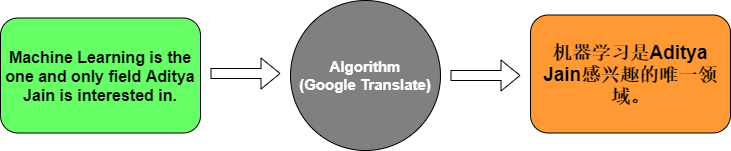

Challenges in Machine Translation:
- Ambiguity

Ex. I went to the bank.
- Idiomatic Expressions

Ex. It's raining cats and dogs.
- Low-Resource Languages

Some languages have very limited data.

Applications of Machine Translation:
- Global Business and E-commerce
-Cross-Cultural Communication
- Multilingual Content Creation
- Language Learning



## Neural Machine Translation:

Neural Machine Translation is a data-driven approach where a single large neural network learns to represent both the source language and the target language, and to directly map between them.
Instead of using manually defined rules or phrase tables, it learns translation patterns automatically from large datasets of bilingual text.

### Key Components of Neural Machine Translation:

<img src="https://drive.google.com/thumbnail?id=1xMmuMvOaYI73cYhQ1lbE5pIjDPWXhfgq&sz=w1000" width="600">


In [1]:
#!pip install tensorflow

In [2]:
import tensorflow as tf
from tensorflow.keras.preprocessing.text import Tokenizer
import numpy as np

# Example bilingual dataset
english_sentences = ["Hello.", "How are you?", "This is a machine translation example."]
french_sentences = ["Bonjour.", "Comment ça va?", "Ceci est un exemple de traduction automatique."]

# Tokenize the english sentences
tokenizer_eng = Tokenizer()
tokenizer_eng.fit_on_texts(english_sentences) # Tokenize words and assign an integer ID to each unique word
eng_sequences = tokenizer_eng.texts_to_sequences(english_sentences) # Returns a list of tokens replaced by their index. Note: words index will start from 1 because 0 is reserved by default for padding (not assigned to any word).
print(f"eng_sequences = {eng_sequences}")
eng_word_index = tokenizer_eng.word_index # Returns the dictionary created by the tokenizer dict {word: index}.
print(f"eng_word_index = {eng_word_index}")

eng_sequences = [[1], [2, 3, 4], [5, 6, 7, 8, 9, 10]]
eng_word_index = {'hello': 1, 'how': 2, 'are': 3, 'you': 4, 'this': 5, 'is': 6, 'a': 7, 'machine': 8, 'translation': 9, 'example': 10}


In [3]:
# Tokenize the french sentences
tokenizer_frn = Tokenizer()
tokenizer_frn.fit_on_texts(french_sentences)
frn_sequences = tokenizer_frn.texts_to_sequences(french_sentences)

print(f"frn_sequences = {frn_sequences}")
frn_word_index = tokenizer_frn.word_index
print(f"frn_word_index = {frn_word_index}")

frn_sequences = [[1], [2, 3, 4], [5, 6, 7, 8, 9, 10, 11]]
frn_word_index = {'bonjour': 1, 'comment': 2, 'ça': 3, 'va': 4, 'ceci': 5, 'est': 6, 'un': 7, 'exemple': 8, 'de': 9, 'traduction': 10, 'automatique': 11}


In [4]:
from tensorflow.keras.preprocessing.sequence import pad_sequences

# Padding sequences
eng_padded = pad_sequences(eng_sequences) # makes all sequences the same length by padding with zeros at the beginning (default)
print(f"eng_padded = {eng_padded}")

eng_padded = [[ 0  0  0  0  0  1]
 [ 0  0  0  2  3  4]
 [ 5  6  7  8  9 10]]


In [5]:
frn_padded = pad_sequences(frn_sequences)
frn_padded

array([[ 0,  0,  0,  0,  0,  0,  1],
       [ 0,  0,  0,  0,  2,  3,  4],
       [ 5,  6,  7,  8,  9, 10, 11]], dtype=int32)

## LSTM Model

<img src="https://drive.google.com/uc?export=view&id=1rUaLO1wEOcUZ10Kwd0nUvS3jQzrqoOcI" width="550">

In [6]:
from sklearn.model_selection import train_test_split

# Train-test split
eng_train, eng_test, frn_train, frn_test = train_test_split(eng_padded, frn_padded, test_size=0.2, random_state=42)

# Define the model
model = tf.keras.Sequential([
    tf.keras.layers.Embedding(input_dim=len(eng_word_index) + 1, output_dim=64),
    tf.keras.layers.LSTM(64),
    tf.keras.layers.RepeatVector(frn_padded.shape[1]), #length of french sentence
    tf.keras.layers.LSTM(64, return_sequences=True),
    tf.keras.layers.TimeDistributed(tf.keras.layers.Dense(len(frn_word_index) + 1, activation='softmax')) #convert to probabilities for each frn word
])

model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])

# Train the model
model.fit(eng_train, np.expand_dims(frn_train, -1), epochs=50, batch_size=1, validation_split=0.2)

# Evaluate the model
loss, accuracy = model.evaluate(eng_test, np.expand_dims(frn_test, -1))
print(f'Test Accuracy: {accuracy}')

Epoch 1/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 7s 7s/step - accuracy: 0.0000e+00 - loss: 2.4865 - val_accuracy: 0.0000e+00 - val_loss: 2.4870
Epoch 2/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 106ms/step - accuracy: 0.5714 - loss: 2.4773 - val_accuracy: 0.0000e+00 - val_loss: 2.4894
Epoch 3/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 111ms/step - accuracy: 0.5714 - loss: 2.4680 - val_accuracy: 0.0000e+00 - val_loss: 2.4921
Epoch 4/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 110ms/step - accuracy: 0.5714 - loss: 2.4579 - val_accuracy: 0.0000e+00 - val_loss: 2.4949
Epoch 5/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 109ms/step - accuracy: 0.5714 - loss: 2.4468 - val_accuracy: 0.0000e+00 - val_loss: 2.4982
Epoch 6/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 102ms/step - accuracy: 0.5714 - loss: 2.4342 - val_accuracy: 0.0000e+00 - val_loss: 2.5017
Epoch 7/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 89ms/step - accuracy: 0.5714 - loss: 2.4197 - val_accuracy: 0.0000e+00 - val_loss: 2.5058
Epoch 8/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 89ms/step - accuracy: 0.5714 - loss: 2.4028 - val_a

In [7]:
# Inference
def translate_sentence(sentence, model, eng_tokenizer, frn_tokenizer):
    sequence = eng_tokenizer.texts_to_sequences([sentence])
    padded_sequence = pad_sequences(sequence, maxlen=eng_padded.shape[1])
    predicted_sequence = model.predict(padded_sequence) #outputs probabilities for each timestep (french padded sentence) and each unique word in the target vocabulary.
    translated_sequence = np.argmax(predicted_sequence, axis=-1) #Returns the index (word ID) with the largest value at each timestep.
    translated_sentence = frn_tokenizer.sequences_to_texts(translated_sequence)
    return translated_sentence[0]

# Example Inference
input_sentence = "How are you?"
translated_sentence = translate_sentence(input_sentence, model, tokenizer_eng, tokenizer_frn)
print(f'Input: {input_sentence}\nTranslation: {translated_sentence}')

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 617ms/step
Input: How are you?
Translation: comment ça va


________________________________________________________________________________________________________________________________________

### Task 1: Understanding the Model Layers

Answer these simple questions in your own words:

1. What does the **Embedding** layer do to a word index?
3. What is the role of the **Encoder LSTM**?
5. What does the **Decoder LSTM** do?
8. Why do we use `softmax` in the final layer?


**Task 1 Answers**

1. **Embedding:** Converts a word index into a learned dense vector that represents useful word features.
2. **Encoder LSTM:** Reads the English input sequence and summarizes its context using hidden and cell states.
3. **Decoder LSTM:** Uses the encoder states and earlier French tokens to predict the next French token.
4. **Softmax:** Converts the output scores into probabilities over the French vocabulary, allowing a word to be selected.

### Task 2:

 Use Case: Language Translation (English-French)

A global e-commerce company wants to expand its reach to French-speaking customers and provide a seamless shopping experience. The company needs a language translation solution to automatically translate product listings, customer reviews, and other relevant content from English to French.

link: https://www.kaggle.com/datasets/devicharith/language-translation-englishfrench

### Task 2 Implementation: English → French Translation

This section builds an **Encoder–Decoder LSTM with teacher forcing** using the Kaggle English–French translation dataset. It is an educational prototype for the e-commerce use case, not a production translation service. Run the cells below in order. The original lecturer example above is preserved.

In [8]:
# Install packages only if your environment needs them
%pip -q install kagglehub pandas scikit-learn tensorflow matplotlib

In [9]:
import os
import numpy as np
import pandas as pd
import kagglehub
import tensorflow as tf
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt

# Reproducible sampling and model initialization
np.random.seed(42)
tf.random.set_seed(42)

# Download the Kaggle dataset and locate the CSV file
dataset_path = kagglehub.dataset_download(
    "devicharith/language-translation-englishfrench"
)
csv_files = [
    os.path.join(root, file)
    for root, _, files in os.walk(dataset_path)
    for file in files if file.lower().endswith('.csv')
]
if not csv_files:
    raise FileNotFoundError("No CSV file found in the downloaded dataset")

csv_path = csv_files[0]
df = pd.read_csv(csv_path)
print("Dataset file:", os.path.basename(csv_path))
print("Dataset shape:", df.shape)
print("Columns:", df.columns.tolist())
display(df.head())

Using Colab cache for faster access to the 'language-translation-englishfrench' dataset.
Dataset file: eng_-french.csv
Dataset shape: (175621, 2)
Columns: ['English words/sentences', 'French words/sentences']


,English words/sentences,French words/sentences
0,Hi.,Salut!
1,Run!,Cours !
2,Run!,Courez !
3,Who?,Qui ?
4,Wow!,Ça alors !


In [10]:
# Select the English and French columns and clean sentence pairs
english_col = next((c for c in df.columns if 'english' in str(c).lower()), None)
french_col = next((c for c in df.columns if 'french' in str(c).lower()), None)
if english_col is None or french_col is None:
    raise ValueError("Could not identify English and French columns. Check df.columns.")

data = df[[english_col, french_col]].dropna().copy()
data.columns = ['english', 'french']
data['english'] = data['english'].astype(str).str.lower().str.strip()
data['french'] = data['french'].astype(str).str.lower().str.strip()
data = data[(data['english'] != '') & (data['french'] != '')]
data = data.drop_duplicates()

# Short sentences and a manageable sample for the class demonstration
data = data[
    (data['english'].str.split().str.len().between(1, 12)) &
    (data['french'].str.split().str.len().between(1, 12))
]
if len(data) < 10:
    raise ValueError("Too few sentence pairs after cleaning")
data = data.sample(n=min(8000, len(data)), random_state=42).reset_index(drop=True)

# Split BEFORE fitting tokenizers to avoid data leakage
train_data, test_data = train_test_split(data, test_size=0.2, random_state=42)
train_data, val_data = train_test_split(train_data, test_size=0.2, random_state=42)
print("Training:", len(train_data), "Validation:", len(val_data), "Testing:", len(test_data))
display(train_data.head())

Training: 5120 Validation: 1280 Testing: 1600


,english,french
617,i'm sure we can manage that.,je suis sûr que nous pouvons gérer ça.
2290,"anyone who protested, lost his job.",tous ceux qui protestaient perdaient leur emploi.
4289,i like listening to you sing.,j'aime vous écouter chanter.
1264,i need them for an exam.,j'en ai besoin pour un examen.
2143,"if you want one, you'll have to find your own.","si tu en veux un, il te faudra trouver le tien."


In [11]:
# Fit tokenizers only on the training sentences
VOCAB_LIMIT = 3000
english_tokenizer = Tokenizer(num_words=VOCAB_LIMIT, oov_token='<OOV>')
french_tokenizer = Tokenizer(num_words=VOCAB_LIMIT, oov_token='<OOV>')

english_tokenizer.fit_on_texts(train_data['english'].tolist())
french_tokenizer.fit_on_texts(
    ('startseq ' + train_data['french'] + ' endseq').tolist()
)

eng_vocab_size = min(VOCAB_LIMIT, len(english_tokenizer.word_index) + 1)
fr_vocab_size = min(VOCAB_LIMIT, len(french_tokenizer.word_index) + 1)
start_id = french_tokenizer.word_index['startseq']
end_id = french_tokenizer.word_index['endseq']

# Use maximum lengths of the selected short training sentences
max_eng_len = max(len(s) for s in english_tokenizer.texts_to_sequences(train_data['english']))
max_fr_len = max(len(s) for s in french_tokenizer.texts_to_sequences(
    ('startseq ' + train_data['french'] + ' endseq').tolist()
))

def make_arrays(frame):
    eng = english_tokenizer.texts_to_sequences(frame['english'].tolist())
    fr = french_tokenizer.texts_to_sequences(
        ('startseq ' + frame['french'] + ' endseq').tolist()
    )
    enc = pad_sequences(eng, maxlen=max_eng_len, padding='post', truncating='post')
    fr_pad = pad_sequences(fr, maxlen=max_fr_len, padding='post', truncating='post')
    dec_input = fr_pad[:, :-1]
    target = fr_pad[:, 1:]
    weights = (target != 0).astype('float32')
    return enc, dec_input, target, weights

eng_train, dec_train, target_train, w_train = make_arrays(train_data)
eng_val, dec_val, target_val, w_val = make_arrays(val_data)
eng_test, dec_test, target_test, w_test = make_arrays(test_data)

print('English vocabulary:', eng_vocab_size)
print('French vocabulary:', fr_vocab_size)
print('Encoder input shape:', eng_train.shape)
print('Decoder input shape:', dec_train.shape)
print('Decoder target shape:', target_train.shape)
print('Example decoder input:', dec_train[0])
print('Example next-token targets:', target_train[0])

English vocabulary: 3000
French vocabulary: 3000
Encoder input shape: (5120, 12)
Decoder input shape: (5120, 14)
Decoder target shape: (5120, 14)
Example decoder input: [   2    4   28  229    8   20  299 2055   29    3    0    0    0    0]
Example next-token targets: [   4   28  229    8   20  299 2055   29    3    0    0    0    0    0]


In [12]:
# Build an Encoder–Decoder LSTM using teacher forcing
from tensorflow.keras.layers import Input, Embedding, LSTM, Dense
from tensorflow.keras.models import Model

latent_dim = 128
embedding_dim = 64

encoder_inputs = Input(shape=(max_eng_len,), name='english_input')
encoder_embedding_layer = Embedding(eng_vocab_size, embedding_dim, mask_zero=True)
encoder_embedding = encoder_embedding_layer(encoder_inputs)
encoder_lstm = LSTM(latent_dim, return_state=True)
_, state_h, state_c = encoder_lstm(encoder_embedding)

# The decoder receives the previous French word during training
decoder_inputs = Input(shape=(None,), name='previous_french_tokens')
decoder_embedding_layer = Embedding(fr_vocab_size, embedding_dim, mask_zero=True)
decoder_embedding = decoder_embedding_layer(decoder_inputs)
decoder_lstm = LSTM(latent_dim, return_sequences=True, return_state=True)
decoder_outputs, _, _ = decoder_lstm(
    decoder_embedding, initial_state=[state_h, state_c]
)
decoder_dense = Dense(fr_vocab_size, activation='softmax')
decoder_outputs = decoder_dense(decoder_outputs)

translation_model = Model([encoder_inputs, decoder_inputs], decoder_outputs)
translation_model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)
translation_model.summary()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ english_input       │ (None, 12)        │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ previous_french_to… │ (None, None)      │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding_1         │ (None, 12, 64)    │    192,000 │ english_input[0]… │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ not_equal           │ (None, 12)        │          0 │ english_input[0]… │
│ (NotEqual)          │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding_2         │ (None, None, 64)  │    192,000 │ previous_french_… │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ lstm_2 (LSTM)       │ [(None, 128),     │     98,816 │ embedding_1[0][0… │
│                     │ (None, 128),      │            │ not_equal[0][0]   │
│                     │ (None, 128)]      │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ lstm_3 (LSTM)       │ [(None, None,     │     98,816 │ embedding_2[0][0… │
│                     │ 128), (None,      │            │ lstm_2[0][1],     │
│                     │ 128), (None,      │            │ lstm_2[0][2]      │
│                     │ 128)]             │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, None,      │    387,000 │ lstm_3[0][0]      │
│                     │ 3000)             │            │                   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 968,632 (3.70 MB)

 Trainable params: 968,632 (3.70 MB)

 Non-trainable params: 0 (0.00 B)

In [13]:
# Train model; padding has weight zero
from tensorflow.keras.callbacks import EarlyStopping

early_stop = EarlyStopping(monitor='val_loss', patience=3, restore_best_weights=True)
history = translation_model.fit(
    [eng_train, dec_train], target_train,
    sample_weight=w_train,
    validation_data=([eng_val, dec_val], target_val, w_val),
    epochs=15,
    batch_size=64,
    callbacks=[early_stop],
    verbose=1
)

Epoch 1/15
80/80 ━━━━━━━━━━━━━━━━━━━━ 47s 452ms/step - accuracy: 0.1229 - loss: 5.5355 - val_accuracy: 0.1442 - val_loss: 4.5130
Epoch 2/15
80/80 ━━━━━━━━━━━━━━━━━━━━ 39s 427ms/step - accuracy: 0.1548 - loss: 4.7048 - val_accuracy: 0.1765 - val_loss: 4.3444
Epoch 3/15
80/80 ━━━━━━━━━━━━━━━━━━━━ 40s 417ms/step - accuracy: 0.1660 - loss: 4.5403 - val_accuracy: 0.1897 - val_loss: 4.2281
Epoch 4/15
80/80 ━━━━━━━━━━━━━━━━━━━━ 41s 422ms/step - accuracy: 0.1773 - loss: 4.4154 - val_accuracy: 0.2081 - val_loss: 4.1316
Epoch 5/15
80/80 ━━━━━━━━━━━━━━━━━━━━ 31s 392ms/step - accuracy: 0.1915 - loss: 4.3132 - val_accuracy: 0.2203 - val_loss: 4.0539
Epoch 6/15
80/80 ━━━━━━━━━━━━━━━━━━━━ 32s 398ms/step - accuracy: 0.1996 - loss: 4.2257 - val_accuracy: 0.2242 - val_loss: 3.9889
Epoch 7/15
80/80 ━━━━━━━━━━━━━━━━━━━━ 41s 398ms/step - accuracy: 0.2049 - loss: 4.1421 - val_accuracy: 0.2285 - val_loss: 3.9223
Epoch 8/15
80/80 ━━━━━━━━━━━━━━━━━━━━ 44s 443ms/step - accuracy: 0.2102 - loss: 4.0533 - val_accu

In [14]:
# Evaluate on held-out sentence pairs (teacher-forced token prediction)
test_results = translation_model.evaluate(
    [eng_test, dec_test], target_test,
    sample_weight=w_test, verbose=0, return_dict=True
)
print('Test results:', {k: round(float(v), 4) for k, v in test_results.items()})
print('Note: token prediction metrics do not measure complete sentence translation quality.')

Test results: {'accuracy': 0.2827, 'loss': 3.4037}
Note: token prediction metrics do not measure complete sentence translation quality.


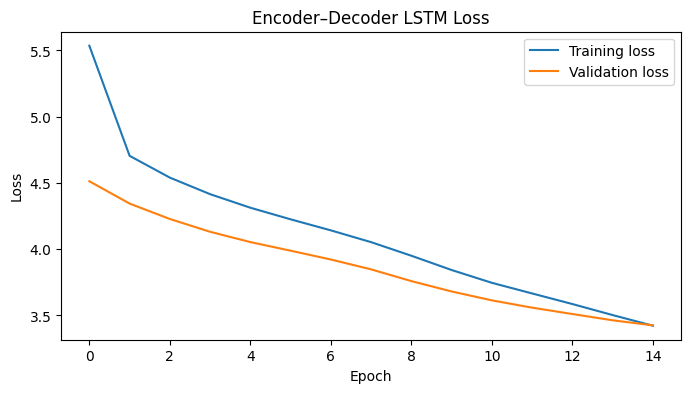

In [15]:
# Plot train and validation loss
plt.figure(figsize=(8, 4))
plt.plot(history.history['loss'], label='Training loss')
plt.plot(history.history['val_loss'], label='Validation loss')
plt.title('Encoder–Decoder LSTM Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.show()

In [16]:
# Create inference models that reuse the trained layers
encoder_model = Model(encoder_inputs, [state_h, state_c])

inf_token = Input(shape=(1,), name='current_french_token')
inf_h = Input(shape=(latent_dim,), name='decoder_hidden_state')
inf_c = Input(shape=(latent_dim,), name='decoder_cell_state')
inf_embedding = decoder_embedding_layer(inf_token)
inf_output, next_h, next_c = decoder_lstm(
    inf_embedding, initial_state=[inf_h, inf_c]
)
inf_probs = decoder_dense(inf_output)
decoder_model = Model([inf_token, inf_h, inf_c], [inf_probs, next_h, next_c])
print('Inference models ready')

Inference models ready


In [17]:
# Translate one English sentence, predicting French tokens one at a time
def translate_sentence(sentence):
    sequence = english_tokenizer.texts_to_sequences([sentence.lower().strip()])
    padded = pad_sequences(sequence, maxlen=max_eng_len, padding='post', truncating='post')
    states = encoder_model.predict(padded, verbose=0)
    current_token = np.array([[start_id]], dtype=np.int32)
    translated_words = []

    for _ in range(max_fr_len - 1):
        probabilities, h, c = decoder_model.predict([current_token] + states, verbose=0)
        next_id = int(np.argmax(probabilities[0, -1, :]))
        if next_id in (0, end_id):
            break
        word = french_tokenizer.index_word.get(next_id, '')
        if word and word != 'startseq':
            translated_words.append(word)
        current_token = np.array([[next_id]], dtype=np.int32)
        states = [h, c]
    return ' '.join(translated_words)

# Illustrative examples. Quality depends on the training data.
examples = ['Hello', 'Thank you', 'Good morning', 'I love you',
            'How are you', 'This is a good product', 'I like this product']
for english in examples:
    print('English:', english)
    print('Predicted French:', translate_sentence(english))
    print('-' * 45)

English: Hello
Predicted French: <OOV>
---------------------------------------------
English: Thank you
Predicted French: nous <OOV>
---------------------------------------------
English: Good morning
Predicted French: <OOV>
---------------------------------------------
English: I love you
Predicted French: je suis pas
---------------------------------------------
English: How are you
Predicted French: nous êtes <OOV>
---------------------------------------------
English: This is a good product
Predicted French: c'est une <OOV>
---------------------------------------------
English: I like this product
Predicted French: je suis <OOV>
---------------------------------------------


In [18]:
# Compare predictions against five held-out, original reference pairs
for _, row in test_data.head(5).iterrows():
    print('English:', row['english'])
    print('Reference French:', row['french'])
    print('Predicted French:', translate_sentence(row['english']))
    print('-' * 55)

English: you don't know tom as well as you think you do.
Reference French: vous ne connaissez pas tom aussi bien que vous ne le pensez.
Predicted French: je ne suis pas que je ne pas pas de <OOV>
-------------------------------------------------------
English: that's not what it means.
Reference French: ce n'est pas ce que ça veut dire.
Predicted French: c'est ce que je ne pas pas
-------------------------------------------------------
English: this word comes from greek.
Reference French: ce mot provient du grec.
Predicted French: c'est <OOV>
-------------------------------------------------------
English: please correct me if i make a mistake.
Reference French: corrige-moi si je fais une erreur, s'il te plaît.
Predicted French: nous avons <OOV> de <OOV> de <OOV>
-------------------------------------------------------
English: have they spotted you?
Reference French: vous ont-ils repérés ?
Predicted French: nous <OOV> <OOV>
-------------------------------------------------------


### Task 2 Conclusion

An English-to-French neural machine translation prototype was implemented with tokenization, sequence padding, and an encoder–decoder LSTM trained using teacher forcing. Training and validation losses and held-out examples are displayed above. The model demonstrates the translation workflow relevant to an e-commerce setting, but its usefulness for actual product listings and customer reviews is limited by the small, general-purpose training sample, vocabulary restrictions, and simplified architecture. The quality of its generated sentences should be judged from the displayed comparisons rather than token accuracy alone.

Limitations and Future Improvements

Although the Encoder–Decoder LSTM model was successfully trained, some translations were inaccurate or contained out-of-vocabulary (OOV) tokens.

The model could be improved by:

Using more training data to learn a wider variety of translation patterns.

Increasing the vocabulary size to reduce OOV predictions.

Applying padding masking (mask_zero=True) to help the LSTM ignore padded tokens.

Using BLEU score to evaluate translation quality more effectively than token-level accuracy alone.

These improvements could help produce more accurate and meaningful French translations.